# Diabetes Disease Progression Prediction

A regression project predicting quantitative diabetes disease progression one year after baseline, using the Diabetes dataset (442 patients, 10 baseline physiological variables: age, sex, BMI, average blood pressure, and six blood serum measurements).

**Goal:** predict a continuous disease-progression score from baseline patient measurements, to explore which physiological factors most strongly drive disease progression.

**Tools:** NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
np.random.seed(42)


## 1. Load and explore the dataset

In [2]:
data = load_diabetes()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["progression"] = data.target

print("Dataset shape:", df.shape)
df.describe().T


Dataset shape: (442, 11)


             count          mean        std        min        25%         50%         75%         max
age          442.0 -2.511817e-19   0.047619  -0.107226  -0.037299    0.005383    0.038076    0.110727
sex          442.0  1.230790e-17   0.047619  -0.044642  -0.044642   -0.044642    0.050680    0.050680
bmi          442.0 -2.245564e-16   0.047619  -0.090275  -0.034229   -0.007284    0.031248    0.170555
bp           442.0 -4.797570e-17   0.047619  -0.112399  -0.036656   -0.005670    0.035644    0.132044
s1           442.0 -1.381499e-17   0.047619  -0.126781  -0.034248   -0.004321    0.028358    0.153914
s2           442.0  3.918434e-17   0.047619  -0.115613  -0.030358   -0.003819    0.029844    0.198788
s3           442.0 -5.777179e-18   0.047619  -0.102307  -0.035117   -0.006584    0.029312    0.181179
s4           442.0 -9.042540e-18   0.047619  -0.076395  -0.039493   -0.002592    0.034309    0.185234
s5           442.0  9.268604e-17   0.047619  -0.126097  -0.033246   -0.001947    0

## 2. Explore relationships between features and disease progression

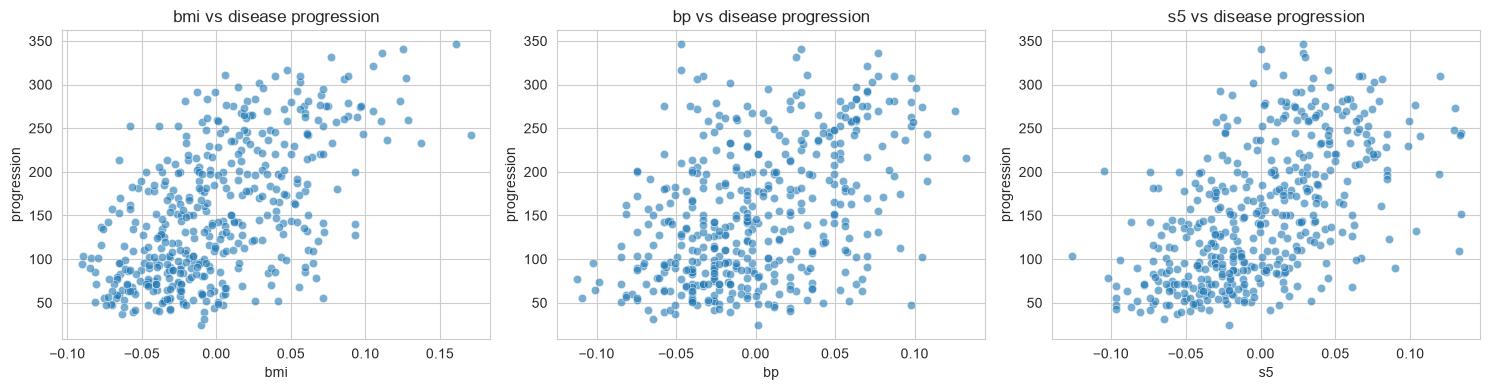

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["bmi", "bp", "s5"]):
    sns.scatterplot(data=df, x=feature, y="progression", ax=ax, alpha=0.6)
    ax.set_title(f"{feature} vs disease progression")
plt.tight_layout()
plt.savefig("feature_vs_progression.png", dpi=120)
plt.show()


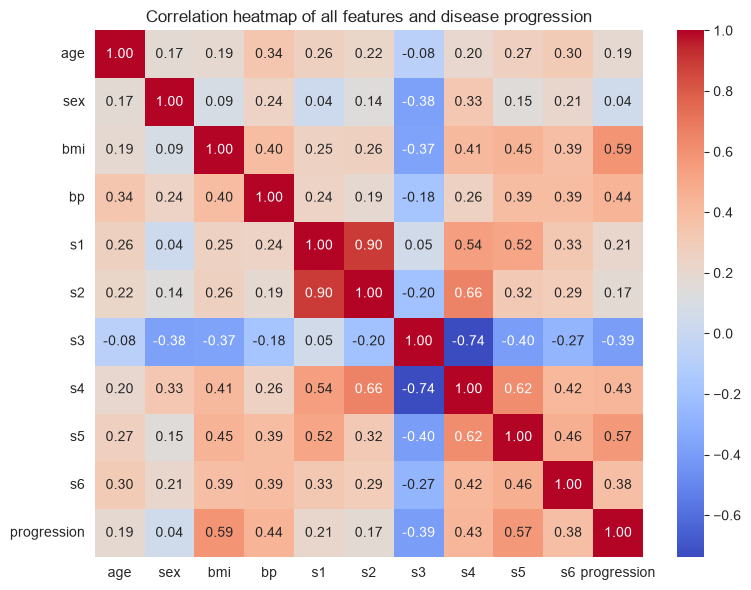

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap of all features and disease progression")
plt.tight_layout()
plt.savefig("diabetes_correlation_heatmap.png", dpi=120)
plt.show()


## 3. Train/test split

In [5]:
X = df[data.feature_names]
y = df["progression"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])


Train size: 353  Test size: 89


## 4. Train models: Linear Regression, Ridge Regression, and Random Forest

In [6]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2 Score": r2_score(y_true, y_pred),
    }

results = pd.DataFrame([
    evaluate("Linear Regression", y_test, y_pred_lin),
    evaluate("Ridge Regression", y_test, y_pred_ridge),
    evaluate("Random Forest", y_test, y_pred_rf),
])
results


               Model        MAE       RMSE  R2 Score
0  Linear Regression  42.794095  53.853446  0.452603
1   Ridge Regression  46.138858  55.474462  0.419153
2      Random Forest  44.276124  54.461217  0.440178

## 5. Predicted vs actual progression scores

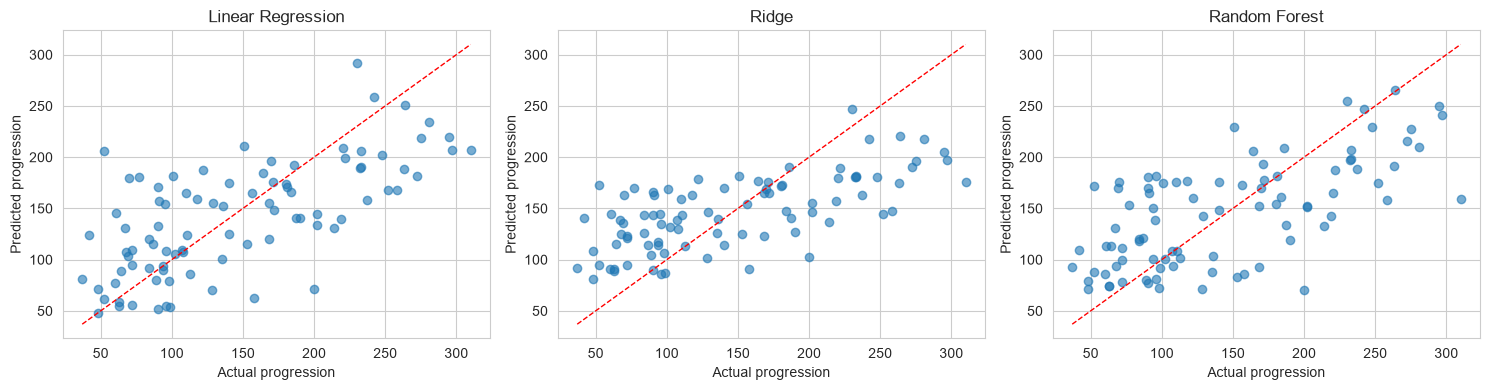

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, preds) in zip(axes, [("Linear Regression", y_pred_lin), ("Ridge", y_pred_ridge), ("Random Forest", y_pred_rf)]):
    ax.scatter(y_test, preds, alpha=0.6)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", linewidth=1)
    ax.set_xlabel("Actual progression")
    ax.set_ylabel("Predicted progression")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("predicted_vs_actual.png", dpi=120)
plt.show()


## 6. Which features matter most?

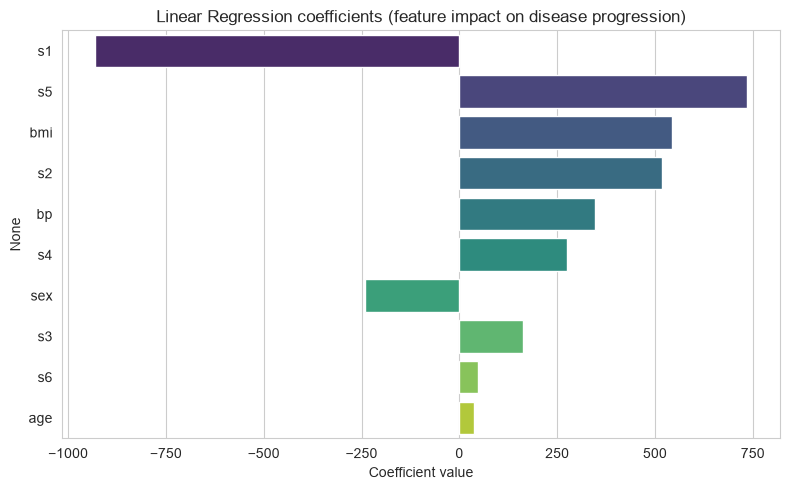

s1    -931.488846
s5     736.198859
bmi    542.428759
s2     518.062277
bp     347.703844
s4     275.317902
sex   -241.964362
s3     163.419983
s6      48.670657
age     37.904021
dtype: float64

In [8]:
coef_df = pd.Series(lin_reg.coef_, index=data.feature_names).sort_values(key=abs, ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=coef_df.values, y=coef_df.index, palette="viridis")
plt.title("Linear Regression coefficients (feature impact on disease progression)")
plt.xlabel("Coefficient value")
plt.tight_layout()
plt.savefig("diabetes_feature_importance.png", dpi=120)
plt.show()
coef_df


## 7. Summary

Three regression models (Linear Regression, Ridge Regression, Random Forest) were trained to predict diabetes disease progression from 10 baseline physiological measurements across 442 patients.

Linear Regression performed best on the held-out test set (R2 = 0.453, MAE = 42.8), slightly ahead of Random Forest (R2 = 0.440) and Ridge Regression (R2 = 0.419). An R2 around 0.45 means the model explains a little under half of the variance in disease progression from baseline measurements alone, which is a reasonable result for this well-known benchmark dataset — it is known to be a genuinely hard regression problem due to low feature-target correlation.

By coefficient magnitude, the strongest predictors in the linear model are 's1' (total serum cholesterol), 's5' (a blood serum measurement related to triglyceride levels), and 'bmi'. Note that 's1' and 's2' are correlated serum measurements, so individual coefficient magnitudes for these two should be read with some caution (multicollinearity can inflate or flip the sign of correlated features) — but 'bmi', 'bp', and 's5' having consistently high impact lines up with established clinical risk factors for diabetes severity.

This notebook demonstrates an end-to-end supervised regression workflow: data loading, exploratory analysis, model training, multi-model comparison, and interpretation of feature impact.
